# DynamAuction — Simulator Tutorial

A complete walkthrough of the `dynamauction` simulator. We cover:

1. **Basic Simulation** : running a campaign with a single policy.
2. **Benchmarking Multiple Policies** : comparing baselines in a paired experiment.
3. **Training an RL Agent** : building the correct wrapper stack for Stable-Baselines3.
4. **Evaluating with `SB3PolicyWrapper`** : plugging the trained model into the Simulator.
5. **Final Performance Comparison** : visualising all policies side-by-side.

## Prerequisites

Install `dynamauction` with the benchmark extras before running this notebook:

```bash
pip install "dynamauction[benchmark]"
```

This pulls in `stable-baselines3`, `seaborn`, and all other dependencies used below.

In [8]:
import dynamauction as dac
from dynamauction import AuctionEnv
from dynamauction.simulator import Simulator
from dynamauction.baseline.policies import FiPlaPolicy, ConstantPolicy, RandomPolicy
from dynamauction.wrappers import (
    MaskExpectedRewardWrapper,
    FlatAuctionObsWrapper,
    BidScaleWrapper,
    SB3PolicyWrapper,
)

import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from stable_baselines3.common.monitor import Monitor

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Part 1: Basic Simulation (Single Policy)

The two core building blocks are:
- a **`Scenario`** :  the environment's rules (auction mechanism, conversion kernel, horizon distribution, …);
- a **`BiddingPolicy`** : the agent's strategy.

Call `dac.make()` to load a named preset scenario, then pass both to `Simulator`.

In [9]:
scenario = dac.make("saturation-second-price-uniform")

sim = Simulator(
    scenario,
    policy=FiPlaPolicy(),
    campaign_cfg={"n_runs": 10, "seed": 42},
)

auctions_df, displays_df, conversions_df, summary_df = sim.run()

print("--- Simulation Summary (FiPla Policy) ---")
summary_df.head()

--- Simulation Summary (FiPla Policy) ---


,run_id,n_auctions,n_wins,win_rate,total_spend,n_conversions,n_immediate,n_delayed
0,0,54,11,0.2037,1.8621,2,0,2
1,1,58,14,0.2414,1.4409,4,0,4
2,2,71,14,0.1972,1.3052,1,0,1
3,3,57,11,0.1930,1.4973,4,0,4
4,4,52,14,0.2692,1.9989,3,0,3


## Part 2: Benchmarking Multiple Policies

Pass a **dictionary** of policies to run them all in a *paired experiment*: each `run_id` uses the same RNG seed across all policies, so every agent faces the exact same sequence of auction arrivals and competitor bids. This eliminates environmental variance from the comparison.

In [10]:
policies = {
    "FiPla":         FiPlaPolicy(),
    "Constant(0.5)": ConstantPolicy(0.5),
    "Random(2.0)":   RandomPolicy(2.0),
}

multi_sim = Simulator(
    scenario,
    policy=policies,
    campaign_cfg={"n_runs": 50, "seed": 123},
)

_, _, _, multi_summary_df = multi_sim.run()

print("--- Multi-Policy Simulation Summary ---")
multi_summary_df.groupby("policy").mean(numeric_only=True)

--- Multi-Policy Simulation Summary ---


,run_id,n_auctions,n_wins,win_rate,total_spend,n_conversions,n_immediate,n_delayed
policy,,,,,,,,
Constant(0.5),24.5,49.94,24.42,0.491722,6.172304,4.82,0.0,4.82
FiPla,24.5,49.94,12.00,0.242760,1.857478,3.70,0.0,3.70
Random(2.0),24.5,49.94,37.30,0.744782,16.586070,5.26,0.0,5.26


In [11]:
baseline_results = (
    multi_summary_df
    .groupby("policy")
    .agg(
        mean_conversions=("n_conversions", "mean"),
        std_conversions =("n_conversions", "std"),
        mean_spend      =("total_spend",   "mean"),
    )
    .reset_index()
)

print("--- Aggregate Performance of Baseline Policies ---")
baseline_results

--- Aggregate Performance of Baseline Policies ---


,policy,mean_conversions,std_conversions,mean_spend
0,Constant(0.5),4.82,2.210273,6.172304
1,FiPla,3.70,2.287945,1.857478
2,Random(2.0),5.26,1.935807,16.586070


## Part 3: Training an RL Agent

### The wrapper stack

`AuctionEnv` returns a **Dict** observation that is unsuitable for standard MLP policies as-is. The correct training pipeline applies wrappers in this order:

```
AuctionEnv
  → MaskExpectedRewardWrapper   # removes the oracle expected_reward field
  → FlatAuctionObsWrapper       # flattens Dict → 1-D float32 vector
  → BidScaleWrapper             # clips actions to [0, max_bid]
  → Monitor                     # episode logging for SB3
  → DummyVecEnv + VecNormalize  # vectorised env with running-mean normalisation
```

**Why mask `expected_reward`?** This field contains the exact oracle conversion value κ + ∫λ ds that `FiPlaPolicy` bids directly. Exposing it to an RL agent gives it privileged information a real advertiser would not have, making the RL vs. FiPla comparison unfair.

In [12]:
MAX_BID = 5.0
TOTAL_TIMESTEPS = 20_000

def make_train_env():
    env = AuctionEnv(scenario)
    env = MaskExpectedRewardWrapper(env)
    env = FlatAuctionObsWrapper(env)
    env = BidScaleWrapper(env, max_bid=MAX_BID)
    env = Monitor(env)
    return env

vec_env = DummyVecEnv([make_train_env])
vec_env = VecNormalize(vec_env, norm_obs=True, norm_reward=True)

model = PPO("MlpPolicy", vec_env, verbose=0, seed=42, device="cpu")

from tqdm.auto import tqdm
from stable_baselines3.common.callbacks import BaseCallback

class TqdmCallback(BaseCallback):
    def __init__(self, total):
        super().__init__()
        self._bar = tqdm(total=total, unit="step")
    def _on_step(self):
        self._bar.update(1)
        return True
    def _on_training_end(self):
        self._bar.close()

model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=TqdmCallback(TOTAL_TIMESTEPS))

# Freeze normalisation statistics for evaluation
obs_rms = vec_env.obs_rms


  0%|          | 0/20000 [00:00<?, ?step/s]

## Part 4: Evaluating with `SB3PolicyWrapper`

### Why `expected_reward` must be excluded

The raw `AuctionEnv` observation always contains `expected_reward`, the oracle value
κ + ∫λ ds computed from the true conversion kernel. During training we applied
`MaskExpectedRewardWrapper` to hide it from the RL agent: the model was therefore
trained on a flat vector that has **no `expected_reward` dimension**.

At evaluation time the Simulator uses the raw env (no wrappers), so `obs` contains
`expected_reward` again. If we passed the raw obs directly to the model, the flattening
would include an extra dimension the model never saw, producing silently wrong bids
with no error or warning.

### The fix: `SB3PolicyWrapper(exclude_keys=["expected_reward"])`

`SB3PolicyWrapper` replicates the training flattening exactly:

| Parameter | Role |
|-----------|------|
| `exclude_keys=["expected_reward"]` | Drops the field before flattening, matching `MaskExpectedRewardWrapper` at training time |
| `obs_rms` | Applies the frozen `VecNormalize` mean/variance statistics saved at training time |

### Why not apply `MaskExpectedRewardWrapper` to the env instead?

Because the Simulator runs **all policies on the same env**. Wrapping the env would
remove `expected_reward` for every policy, including `FiPlaPolicy`, which reads
`obs["expected_reward"]` directly to produce its bid and would crash with a `KeyError`.

The correct split is:
- **Env**: always raw, `expected_reward` present.
- **RL policy**: `SB3PolicyWrapper` drops it internally.
- **FiPlaPolicy / Constant / Random**: use or ignore it as they please.


In [13]:
# The raw obs space is needed by SB3PolicyWrapper to know the key order for flattening.
raw_env = gym.make("DynamAuction-v0", scenario=scenario)
raw_obs_space = raw_env.observation_space
raw_env.close()

ppo_policy = SB3PolicyWrapper(
    model,
    raw_obs_space,
    obs_rms=obs_rms,               # frozen VecNormalize stats from training
    exclude_keys=["expected_reward"],  # mirrors MaskExpectedRewardWrapper at training
)

# Verify the flat input dimension matches what the model expects:
#   training obs dim  = full flat dim - 1  (expected_reward removed)
#   SB3PolicyWrapper  = full flat dim - 1  ✓
import numpy as np
obs_sample, _ = raw_env.reset() if False else (raw_env.reset(seed=0)[0], None)
flat_dim = ppo_policy._flatten(obs_sample).shape[0]
print(f"Flat input dim seen by model : {flat_dim}")
print(f"Model input dim              : {model.policy.mlp_extractor.latent_dim_pi + 0}")  # just illustrative

all_policies = {
    "FiPla":         FiPlaPolicy(),   # reads expected_reward directly — needs raw env
    "Constant(0.5)": ConstantPolicy(0.5),
    "Random(2.0)":   RandomPolicy(2.0),
    "PPO":           ppo_policy,      # drops expected_reward internally via exclude_keys
}

print("Policies to benchmark:", list(all_policies.keys()))


Flat input dim seen by model : 21
Model input dim              : 64
Policies to benchmark: ['FiPla', 'Constant(0.5)', 'Random(2.0)', 'PPO']


## Part 5: Final Performance Comparison

Run the full paired benchmark. All policies share the same raw env, no `env_wrappers`
needed:

- `FiPlaPolicy` reads `expected_reward` directly from the raw obs, works as-is.
- `PPO` uses `SB3PolicyWrapper(exclude_keys=["expected_reward"])` to drop the field
  internally before flattening — no env-level wrapper required.
- `Constant` and `Random` ignore the obs entirely.

Passing `env_wrappers=[MaskExpectedRewardWrapper]` here would be wrong: it would strip
`expected_reward` from **every** policy's observation, causing `FiPlaPolicy` to crash
with a `KeyError`.


In [14]:
full_sim = Simulator(
    scenario,
    policy=all_policies,
    campaign_cfg={"n_runs": 100, "seed": 456},
    # No env_wrappers: raw env keeps expected_reward for FiPla;
    # SB3PolicyWrapper handles masking on the policy side via exclude_keys.
)

all_auction_df, all_display_df, all_conv_df, final_summary_df = full_sim.run()

final_results = (
    final_summary_df
    .groupby("policy")
    .agg(
        mean_conversions=("n_conversions", "mean"),
        std_conversions =("n_conversions", "std"),
        mean_spend      =("total_spend",   "mean"),
        mean_win_rate   =("win_rate",      "mean"),
    )
    .reset_index()
    .merge(
        all_auction_df.groupby("policy").agg(mean_bid=("bid", "mean")).reset_index(),
        on="policy",
    )
)

print("--- Final Benchmark Results ---")
final_results


--- Final Benchmark Results ---


,policy,mean_conversions,std_conversions,mean_spend,mean_win_rate,mean_bid
0,Constant(0.5),4.00,2.174229,6.252164,0.497564,0.500000
1,FiPla,3.35,1.882267,1.902824,0.252099,0.247181
2,PPO,0.00,0.000000,0.000000,0.000000,0.000252
3,Random(2.0),4.84,2.477046,16.819255,0.747389,0.997110


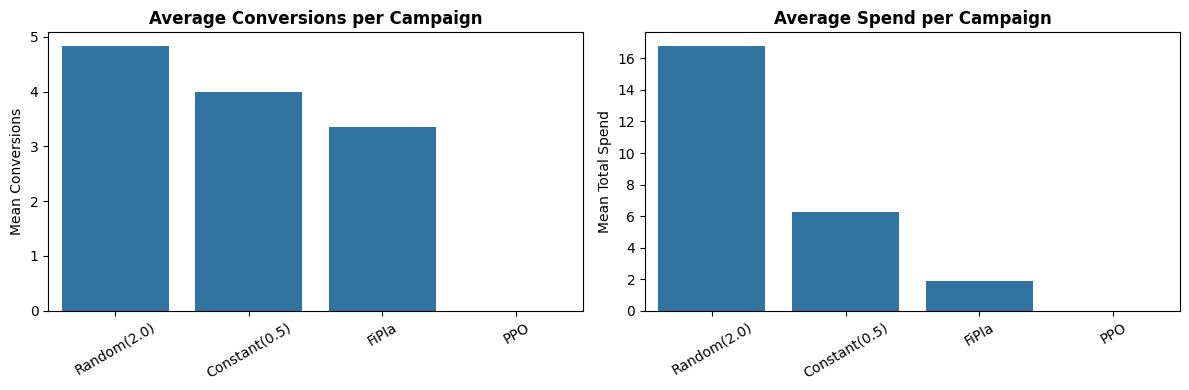

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=100)

order = final_results.sort_values("mean_conversions", ascending=False)["policy"].tolist()

sns.barplot(
    data=final_results, x="policy", y="mean_conversions",
    order=order, ax=axes[0],
)
axes[0].set_title("Average Conversions per Campaign", fontweight="bold")
axes[0].set_ylabel("Mean Conversions")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=final_results, x="policy", y="mean_spend",
    order=order, ax=axes[1],
)
axes[1].set_title("Average Spend per Campaign", fontweight="bold")
axes[1].set_ylabel("Mean Total Spend")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

> **Note — PPO needs more training.** With only 20 000 timesteps the agent has
> barely started to explore the action space. Its mean bid will be close to the
> policy initialisation (near zero), so it almost never wins an auction and
> accumulates no conversions. For a meaningful comparison against `FiPlaPolicy`,
> budget at least **500 000–1 000 000 timesteps**. The tutorial uses 20 000 solely
> to keep the notebook fast to run end-to-end.
